**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import set_seed, SEED, DIMS, get_splits, get_device
from src.representation import train_autoencoder, ae_encode, ae_decode, save_autoencoder

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
print("Device:", get_device())

Device: cuda


**Célula 2 – treinar um autoencoder por dimensão:**

In [2]:
histories, rows = {}, []

for d in DIMS:
    start = time.perf_counter()
    model, history = train_autoencoder(X_train, X_val, latent_dim=d, epochs=50)
    elapsed = time.perf_counter() - start

    save_autoencoder(model, f"models/ae_{d}.pt")                  
    histories[d] = history
    best_epoch = int(np.argmin(history["val_loss"])) + 1          
    rows.append({"dim": d, "ae_val_mse": min(history["val_loss"]),
                 "best_epoch": best_epoch, "train_time_s": elapsed})
    print(f"d={d:3d} | melhor val MSE = {min(history['val_loss']):.5f} (época {best_epoch}) | {elapsed:.1f} s")

d=  2 | melhor val MSE = 0.02382 (época 50) | 160.2 s
d=  8 | melhor val MSE = 0.01228 (época 48) | 48.4 s
d= 16 | melhor val MSE = 0.00977 (época 46) | 31.4 s
d= 32 | melhor val MSE = 0.00789 (época 49) | 48.9 s
d= 64 | melhor val MSE = 0.00728 (época 50) | 34.4 s
d=128 | melhor val MSE = 0.00683 (época 50) | 32.7 s


**Célula 3 – comparar com o PCA:**

 dim  pca_val_mse  ae_val_mse  best_epoch  train_time_s
   2      0.04617     0.02382          50     160.17288
   8      0.02660     0.01228          48      48.41765
  16      0.02038     0.00977          46      31.42144
  32      0.01510     0.00789          49      48.88990
  64      0.01031     0.00728          50      34.42924
 128      0.00627     0.00683          50      32.69449


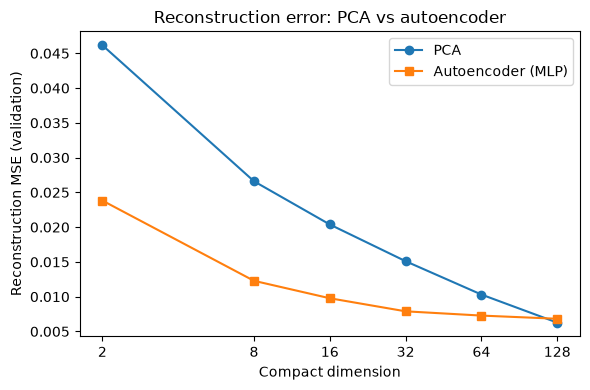

In [3]:
ae_table = pd.DataFrame(rows)
pca_table = pd.read_csv("results/tables/04_pca_reconstruction_mse.csv")

comp = ae_table.merge(pca_table.rename(columns={"val_mse": "pca_val_mse"}), on="dim")
comp = comp[["dim", "pca_val_mse", "ae_val_mse", "best_epoch", "train_time_s"]]
print(comp.round(5).to_string(index=False))
comp.to_csv("results/tables/06_reconstruction_pca_vs_ae.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(comp["dim"], comp["pca_val_mse"], marker="o", label="PCA")
ax.plot(comp["dim"], comp["ae_val_mse"], marker="s", label="Autoencoder (MLP)")
ax.set_xscale("log", base=2)
ax.set_xticks(DIMS, labels=DIMS)
ax.set_xlabel("Compact dimension")
ax.set_ylabel("Reconstruction MSE (validation)")
ax.set_title("Reconstruction error: PCA vs autoencoder")
ax.legend()
plt.tight_layout()
plt.savefig("results/figures/06_reconstruction_pca_vs_ae.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 4 – curvas de treino/validação:**

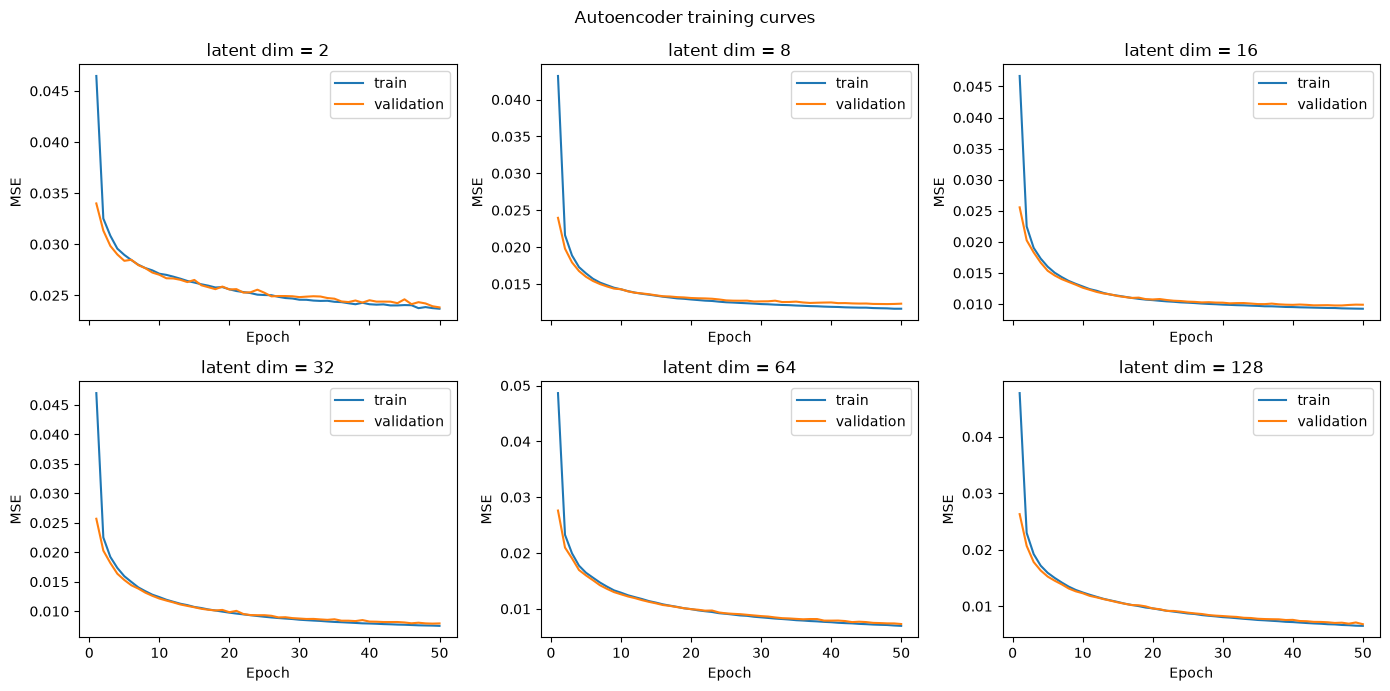

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, d in zip(axes.ravel(), DIMS):
    h = histories[d]
    epochs = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(epochs, h["train_loss"], label="train")
    ax.plot(epochs, h["val_loss"], label="validation")
    ax.set_title(f"latent dim = {d}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.legend()
plt.suptitle("Autoencoder training curves")
plt.tight_layout()
plt.savefig("results/figures/06_ae_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()